# File in cui faccio cose per capire cose


## Capendo come funzionano gli alberi



se ho che   
$ x = 2 \rightarrow y = 1 $  
$ x = 3 \rightarrow y = -1 $  
$ x = 4 \rightarrow y = 1 $   
$ x = 5 \rightarrow y = -1 $  
come fa gli split l'albero?


In [ ]:
import numpy as np 

x_sample = [2,3,4,5,6,7]

def f_star(x):

    return (-1) ** x



step 1: [2, 3, 4, 5, 6, 7] -> x <= 4.5: [2, 3, 4] | x > 4.5: [5, 6, 7]
    step 2: [2, 3, 4] -> x <= 2.5: [2] | x > 2.5: [3, 4]
        step 3: [3, 4] -> x <= 3.5: [3] | x > 3.5: [4]


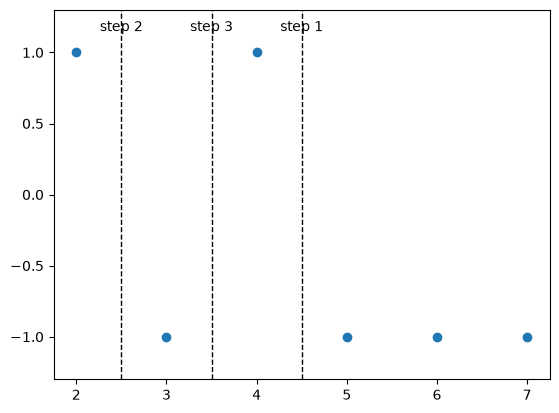

In [16]:
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier

x = np.array(x_sample)
y = [1,-1,1,-1,-1,-1]
clf = DecisionTreeClassifier(max_depth=3).fit(x.reshape(-1, 1), y)
t = clf.tree_

# visita l'albero: per ogni nodo, quali punti contiene e dove li divide
def show_split(node, pts, step=1):
    if t.children_left[node] == -1:
        return
    thr = t.threshold[node]
    left, right = pts[pts <= thr], pts[pts > thr]
    print("    " * (step - 1) + f"step {step}: {pts.tolist()} -> x <= {thr}: {left.tolist()} | x > {thr}: {right.tolist()}")
    plt.axvline(thr, ls="--", color="k", lw=1)
    plt.text(thr, 1.15, f"step {step}", ha="center")
    show_split(t.children_left[node], left, step + 1)
    show_split(t.children_right[node], right, step + 1)

plt.scatter(x, y)
show_split(0, x)
plt.ylim(-1.3, 1.3)
plt.show()

This confirms my intuition on how trees work: the order of the $x$ s matters, because the algorithm splits the interval at some value of $x$ at each iteration.  

(vedi foto lavagna)

## Capendo i grafici di test e train error

<span style="color:red"> How to read:</span> sotto al primo plot e sotto il titolo di ogni sezione raccolgo tutto quello che ho capito. Espandendo le varie sezioni poi, si trovano gli esperimenti e i commenti che mostrano ogni cosa.



In [15]:
%run base.ipynb

mare


[checkpoint] bound: "naive" -> bound_naive, params: []


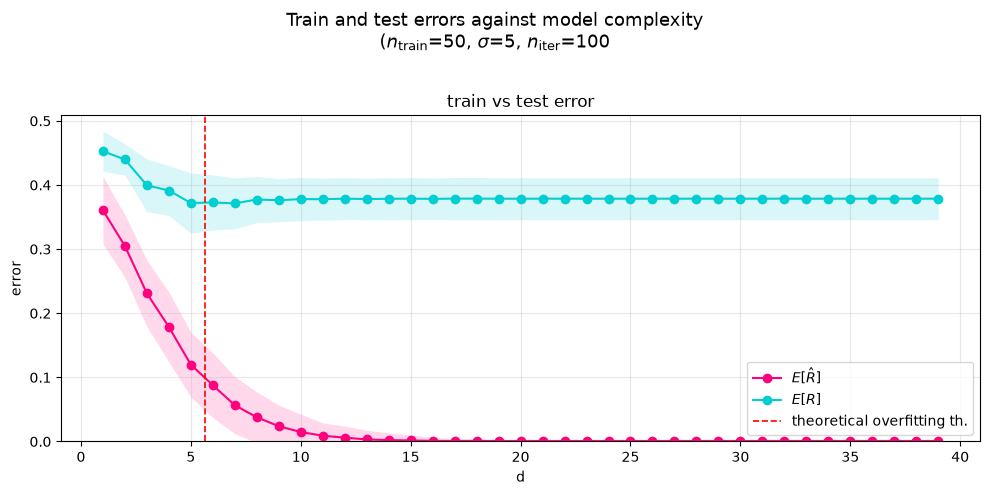

In [4]:
mymodel = DecisionTreeClassifier

from functools import partial

noise_std = 5
num_iter = 100
data_size_tr = 50
supp_size = 10_000
data_size_test = 20_000
num_crossings = 5

gen_fun = partial(sine, m=num_crossings)

x_test = sample_x(data_size_test, N = supp_size)
y_test = sample_y(x=x_test, f=gen_fun, sigma=noise_std)

hat_Rs, Rs, gaps, std_hat_Rs, std_Rs, std_gaps, predictions, x, y, x_grid = main_loop(
    x_test, y_test, n=data_size_tr, N = supp_size, sigma=noise_std, T=num_iter, model=mymodel, f=gen_fun)
plots(hat_Rs, Rs, gaps, std_hat_Rs=std_hat_Rs, std_Rs=std_Rs, std_gaps=std_gaps, n=data_size_tr, 
      sigma=noise_std, T=num_iter, model=mymodel,
      two = False, three = False)


### Cosa mi mostra il grafico e come funziona l'algoritmo: 

IL GRAFICO MOSTRA L'ERRRORE DEL MODELLO APPRESO AD OGNI DEPTH SUL TRAIN E TEST SET (ON AVERAGE).  
 I vari punti sulle curve vengono ognuno dal suo training process: attenzione a NON leggere la curva rosa come se fosse il grafico di un unico trainig process, che mostra la fase di learning. 

L'algoritmo dei decision trees di scikit-learn non ottimizza su tutti i possibili alberi con una data depth massima, ma **ottimizza split per split**, quindi a volte un certo albero con depth $2$ non è fattibile perché richiede un split non ottimale a depth $1$, anche se alla fine sarebbe il migliore (vedi sezione Saturation Depth). Questo fa sì che i ragionamenti che noi facciamo non siano sempre esattamente rispecchiati dagli esperimenti.

Infine, l'algoritmo ad ogni split minimizza l'**impurità pesata** dei suoi figli, che può dare un risultato diverso da contare il numero di misclassified inputs.




### First observations:


- **il train error diminuisce** perché  con una depth maggiore posso classificare meglio, la mia classe è più espressiva.  

- **il test error diminuisce** perché anche sui dati di test pochi split classificheranno male tanti punti.

- **il train error satura a $0$** perché una volta che classifico bene tutti i punti di train, anche se aumento depth non cambia nulla.  

Ma quando mi fermo? Vediamo qui. 


### Saturation depth

**Saturation depth** La depth a cui l'algoritmo smette di splittare è determinata da due cose. 

In primis, il numero dei punti di training: è deterministico che da quando ho un numero di leaf pari al numero dei punti di training, non splitto più e i miei errori stabilizzano entrambi. Comunque, $d = \log_2 n$ non è un threshold esatto: possono stabilizzare prima, se le foglie sono pure anche contenendo più di un punto di training, o dopo, se l'algoritmo costruisce un albero sbilanciato.  

Allo stesso tempo, la depth massima può essere stabilita dal numero dei cambi di segno della funzione sotto, che chiamiamo $m$, in relazione al rumore. In assenza di rumore, quando ho $2^d = m$ (al netto di un + o -1), non splitto più perché ho solo leaf pure (cioè con punti della stessa classe). Con il rumore, questo threshold viene un po' smussato. 

Inoltre, questi threshold non sono sempre esatti perché il modello che apprendo non è sempre il migliore, per come funziona l'algoritmo dei decision trees, detto sopra.

#### Influence of $m$

[checkpoint] bound: "naive" -> bound_naive, params: []


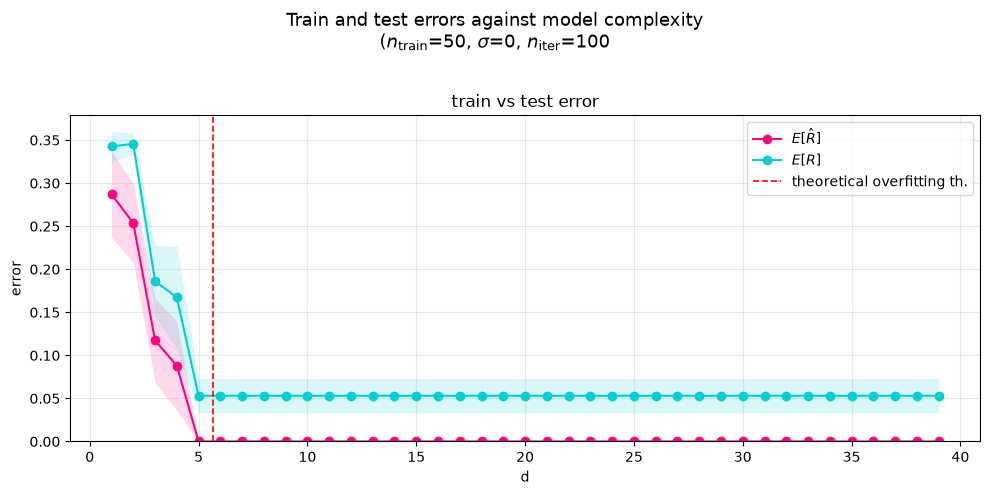

In [25]:
mymodel = DecisionTreeClassifier

from functools import partial

noise_std = 0
num_iter = 100
data_size_tr = 50
supp_size = 10_000
data_size_test = 20_000
num_crossings = 5

gen_fun = partial(sine, m=num_crossings)

x_test = sample_x(data_size_test, N = supp_size)
y_test = sample_y(x=x_test, f=gen_fun, sigma=noise_std)

hat_Rs, Rs, gaps, std_hat_Rs, std_Rs, std_gaps, predictions, x, y, x_grid = main_loop(
    x_test, y_test, n=data_size_tr, N = supp_size, sigma=noise_std, T=num_iter, model=mymodel, f=gen_fun)
plots(hat_Rs, Rs, gaps, std_hat_Rs=std_hat_Rs, std_Rs=std_Rs, std_gaps=std_gaps, n=data_size_tr, 
      sigma=noise_std, T=num_iter, model=mymodel,
      two = False, three = False)

We see that the algorithm stabilizes before the number of splits is enough to get pure nodes (red line).

In [26]:

animation = animate_learned_function(model = mymodel, n = data_size_tr, best_pred = predictions,
                         best_x = x, best_y = y, x_grid = x_grid, f = gen_fun)
HTML(animation.to_jshtml())

Da questo, capiamo che non possiamo sempre aspettarci che l'albero migliore con una certa depth *massima* sia quello che faremmo noi teoricamente, per depth $2$ resta uguale al primo, ed ho plottato l'albero che performa meglio sul train set, tra tutti i $T$ che fittiamo. 

Questo è per **come funzionano gl alberi**: ogni split minimizza indipendentemente dagli altri (tenendo fissi i precedenti e senza considerare i futuri) il Gini index, cioè l'impurità pesata dei suoi figli. Se il primo step, come in qusto caso, è vicino a $8$, quando poi posso farne un secondo a sinistra, vedo che non mi conviene, perchè classificherei male più punti. Invece, faccio uno split che fa diminuire il Gini, cioè la weighted average di $2p(1-p)$ con $p$ porzione di labels positive, in ogni figlio. L'albero migliore che ho in mente io a depth $2$ fa uno split più verso $3$ al primo turno, che però non è ottimale a quella depth in termini di Gini e neanche di numero di misclassified, quindi il mio decision tree non lo farà mai. Fa un altro split che non cambia le predizioni ma diminuisce il Gini.


[checkpoint] bound: "naive" -> bound_naive, params: []


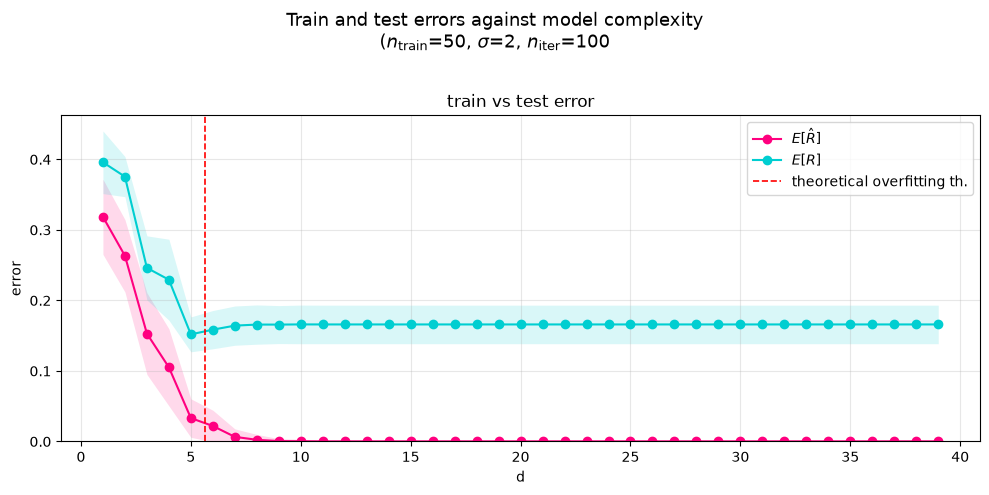

In [23]:
mymodel = DecisionTreeClassifier

from functools import partial

noise_std = 2
num_iter = 100
data_size_tr = 50
supp_size = 10_000
data_size_test = 20_000
num_crossings = 5

gen_fun = partial(sine, m=num_crossings)

x_test = sample_x(data_size_test, N = supp_size)
y_test = sample_y(x=x_test, f=gen_fun, sigma=noise_std)

hat_Rs, Rs, gaps, std_hat_Rs, std_Rs, std_gaps, predictions, x, y, x_grid = main_loop(
    x_test, y_test, n=data_size_tr, N = supp_size, sigma=noise_std, T=num_iter, model=mymodel, f=gen_fun)
plots(hat_Rs, Rs, gaps, std_hat_Rs=std_hat_Rs, std_Rs=std_Rs, std_gaps=std_gaps, n=data_size_tr, 
      sigma=noise_std, T=num_iter, model=mymodel,
      two = False, three = False)

Adding the noise, this is not the case.

In [24]:
animation = animate_learned_function(model = mymodel, n = data_size_tr, best_pred = predictions,
                         best_x = x, best_y = y, x_grid = x_grid, f = gen_fun)
HTML(animation.to_jshtml())

Indeed, just from the data distribution we see that there are not only $6$ ($m+1$) regions. Moreover, recall this plot is for the first learned model, while the test/train curves plot above is for an average of multiple models, trained on a different dataset with possibly more flipped inputs. 

#### Influence of $n$

Ora proviamo ad avere più oscillazioni della funzione sotto e pochi punti di training. Abbiamo visto che con $5$ oscillazioni e noise $2$ il train error va a $0$ intorno a $10$. Vediamo se con pochi punti di training e più oscillazioni va a $0$ prima.

[checkpoint] bound: "naive" -> bound_naive, params: []


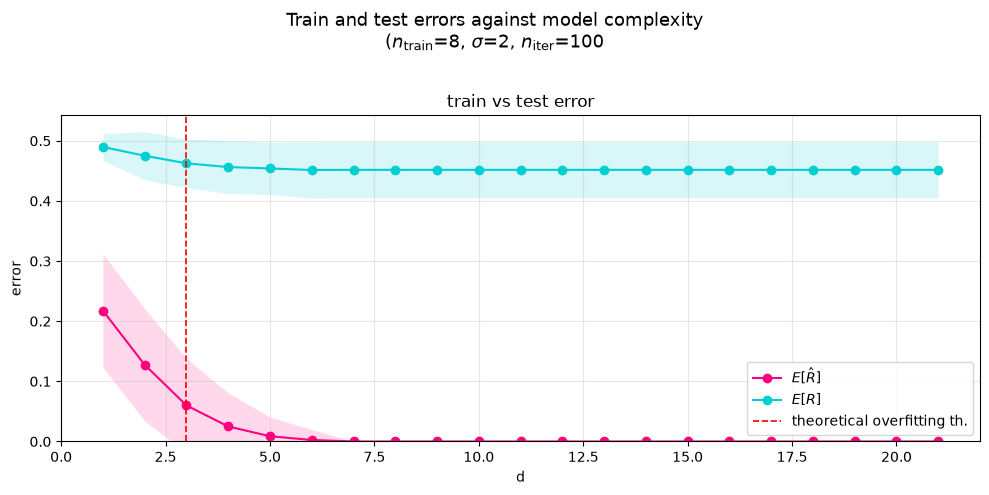

In [20]:
mymodel = DecisionTreeClassifier

from functools import partial

noise_std = 2
num_iter = 100
data_size_tr = 8
supp_size = 10_000
data_size_test = 20_000
num_crossings = 12

gen_fun = partial(sine, m=num_crossings)

x_test = sample_x(data_size_test, N = supp_size)
y_test = sample_y(x=x_test, f=gen_fun, sigma=noise_std)

hat_Rs, Rs, gaps, std_hat_Rs, std_Rs, std_gaps, predictions, x, y, x_grid = main_loop(
    x_test, y_test, n=data_size_tr, N = supp_size, sigma=noise_std, T=num_iter, model=mymodel, f=gen_fun)
plots(hat_Rs, Rs, gaps, std_hat_Rs=std_hat_Rs, std_Rs=std_Rs, std_gaps=std_gaps, n=data_size_tr, 
      sigma=noise_std, T=num_iter, model=mymodel,
      two = False, three = False)

In [22]:
animation = animate_learned_function(model = mymodel, n = data_size_tr, best_pred = predictions,
                         best_x = x, best_y = y, x_grid = x_grid, f = gen_fun)
HTML(animation.to_jshtml())

Chiaramente, non impara la funzione sotto, ma una volta che ha classificato bene i punti di training si ferma. 

### Saturazione test error

Il test error satura anch'esso, perché a una certa il modello che io imparò è sempre lo stesso, perché come discusso finora l'algoritmo si ferma. 

Può fermarsi **prima del train error**, come nel grafico sopra, perché c'è più rumore e quindi gli ultimi split che overfittano il train error non sono importanti per il test, anzi, magari lo peggiorano (vedi discussione sotto). 

- **il test error satura a un livello $>0$** perché c'è una componente di noise che è irriducibile, e perché non ho osservato tutti i punti del mio supporto, quindi alcuni potrei non conoscerli. Vedi i grafici sotto.


Infatti 

(1) $n/N$: ho dei punti nel test set che il mio algoritmo non ha mai visto perché ho $n\ll N$. Allo stesso tempo, anche con $n > N$ e del rumore, entrambi gli errori stabilizzano a $>0$ perché è impossibile classificare perfettamente quando vedo lo stesso input con due etichette diverse. 

(2) $\sigma$: a causa del rumore irriducibile nei dati, ci saranno sempre alcuni punti del test che scappano dalla classificazione imparata dall'algoritmo, che ha fittato il rumore del train. 

Quindi:

quando $n<N$ ho che l'errore di test è maggiore di quello di train; 

quando $\sigma >0$ ho che l'errore di test è maggiore di quello di train;

quando $n>N$ e $\sigma = 0$ sia errore di test sia di train vanno a $0$;

quando $n>N$ e $\sigma > 0$, ho un doppio effetto del rumore: da un lato, impedisce all'errore di train di andare a $0$, e poi crea come al solito una differenza tra il test e il train.  

Il **valore specifico a cui satura il test error** è chiaramente influenzato da $\sigma$ e $n/N$, ma anche dalla complessità della funzione sotto $m$ (perchè mi avvicino a $0.5$), però in relazione al numero di punti che io ho disponibili. 

[checkpoint] bound: "naive" -> bound_naive, params: []


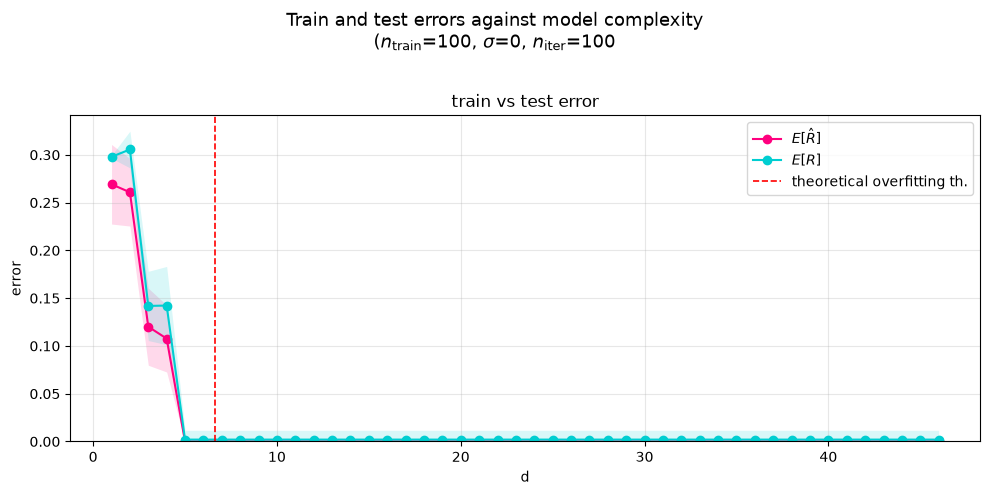

In [28]:
mymodel = DecisionTreeClassifier

from functools import partial

noise_std = 0
num_iter = 100
data_size_tr = 100
supp_size = 20
data_size_test = 20_000
num_crossings = 5

gen_fun = partial(sine, m=num_crossings)

x_test = sample_x(data_size_test, N = supp_size)
y_test = sample_y(x=x_test, f=gen_fun, sigma=noise_std)

hat_Rs, Rs, gaps, std_hat_Rs, std_Rs, std_gaps, predictions, x, y, x_grid = main_loop(
    x_test, y_test, n=data_size_tr, N = supp_size, sigma=noise_std, T=num_iter, model=mymodel, f=gen_fun)
plots(hat_Rs, Rs, gaps, std_hat_Rs=std_hat_Rs, std_Rs=std_Rs, std_gaps=std_gaps, n=data_size_tr, 
      sigma=noise_std, T=num_iter, model=mymodel,
      two = False, three = False)

Se io glieli faccio vedere tutti, con $0$ noise, classifica bene anche il test. 

[checkpoint] bound: "naive" -> bound_naive, params: []


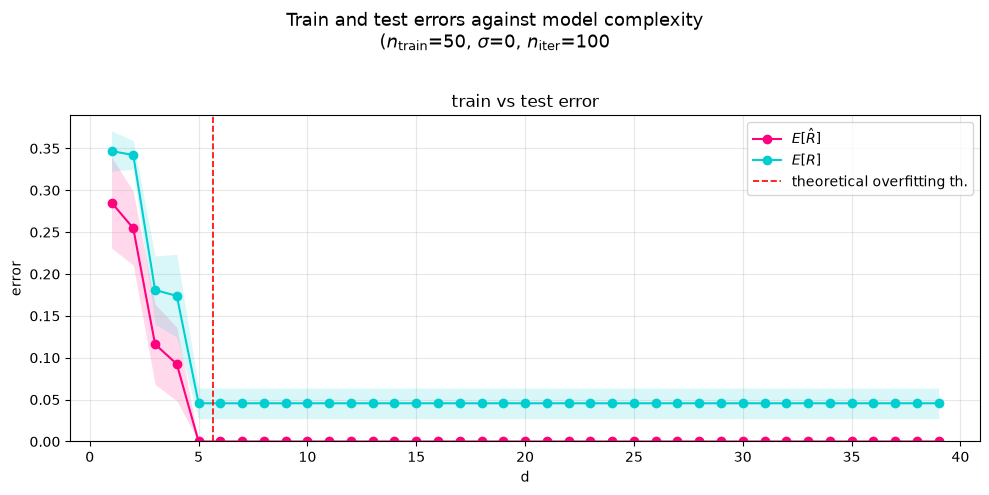

In [31]:
mymodel = DecisionTreeClassifier

from functools import partial

noise_std = 0
num_iter = 100
data_size_tr = 50
supp_size = 10_000
data_size_test = 20_000
num_crossings = 5

gen_fun = partial(sine, m=num_crossings)

x_test = sample_x(data_size_test, N = supp_size)
y_test = sample_y(x=x_test, f=gen_fun, sigma=noise_std)

hat_Rs, Rs, gaps, std_hat_Rs, std_Rs, std_gaps, predictions, x, y, x_grid = main_loop(
    x_test, y_test, n=data_size_tr, N = supp_size, sigma=noise_std, T=num_iter, model=mymodel, f=gen_fun)
plots(hat_Rs, Rs, gaps, std_hat_Rs=std_hat_Rs, std_Rs=std_Rs, std_gaps=std_gaps, n=data_size_tr, 
      sigma=noise_std, T=num_iter, model=mymodel,
      two = False, three = False)

Se io non glieli faccio vedere tutti, anche se ho noise $0$ comunque il test error sta un po' sopra perché il modello classifica degli input che non ha mai visto. 

[checkpoint] bound: "naive" -> bound_naive, params: []


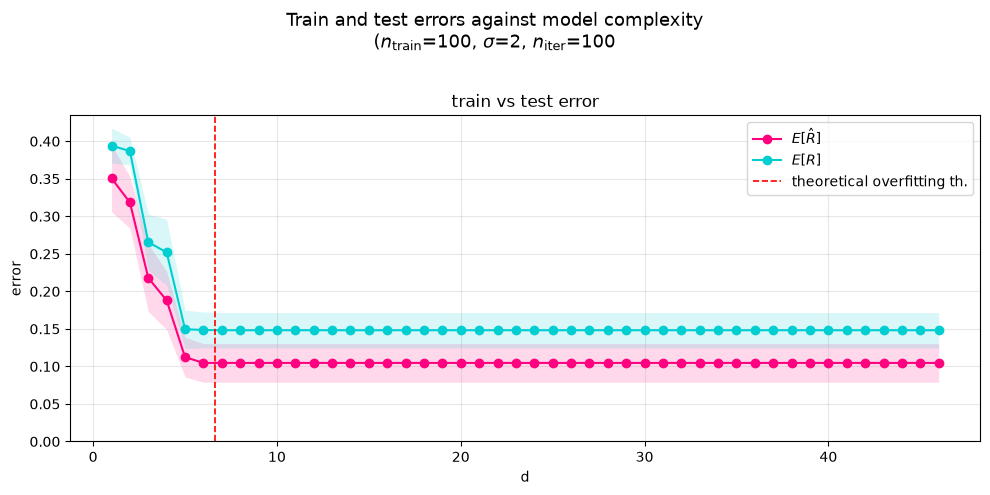

In [35]:
mymodel = DecisionTreeClassifier

from functools import partial

noise_std = 2
num_iter = 100
data_size_tr = 100
supp_size = 20
data_size_test = 20_000
num_crossings = 5

gen_fun = partial(sine, m=num_crossings)

x_test = sample_x(data_size_test, N = supp_size)
y_test = sample_y(x=x_test, f=gen_fun, sigma=noise_std)

hat_Rs, Rs, gaps, std_hat_Rs, std_Rs, std_gaps, predictions, x, y, x_grid = main_loop(
    x_test, y_test, n=data_size_tr, N = supp_size, sigma=noise_std, T=num_iter, model=mymodel, f=gen_fun)
plots(hat_Rs, Rs, gaps, std_hat_Rs=std_hat_Rs, std_Rs=std_Rs, std_gaps=std_gaps, n=data_size_tr, 
      sigma=noise_std, T=num_iter, model=mymodel,
      two = False, three = False)

Al contrario, con $\sigma = 2$ ma osservando tutti i punti del supporto, ho che entrambi stabilizzano sopra lo $0$. 

- Il train error non va a $0$ perché ho alcune labels classificate in due modi diversi, quindi è impossibile che vada a $0$.  

- Non cambia nulla se cambio il numero i punti nel test set. 

- L'errore di test è comunque un po' più alto perché ho fittato il rumore del train. 


Nota: il valore a cui satura l'errore di test è quindi influenzato da $\sigma$, $n/N$, ma anche dalla complessità della funzione sotto $m$ (numero di cambi di segno), secondo me in relazione al numero di punti che incontro o alla grandezza del supporto. 

Dal file ```esperimentini.ipynb``` vediamo che con $50$ crossings iniziamo a aumentar everso $0.5$ test error. Vediamo se però aumentiamo anche il numero di training points. 

[checkpoint] bound: "naive" -> bound_naive, params: []


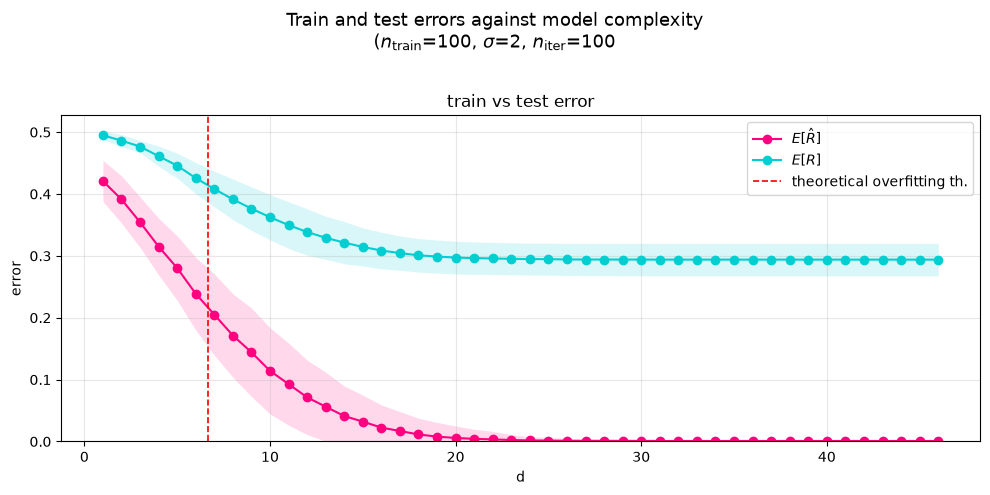

In [39]:
mymodel = DecisionTreeClassifier

from functools import partial

noise_std = 2
num_iter = 100
data_size_tr = 100
supp_size = 10_000
data_size_test = 20_000
num_crossings = 50

gen_fun = partial(sine, m=num_crossings)

x_test = sample_x(data_size_test, N = supp_size)
y_test = sample_y(x=x_test, f=gen_fun, sigma=noise_std)

hat_Rs, Rs, gaps, std_hat_Rs, std_Rs, std_gaps, predictions, x, y, x_grid = main_loop(
    x_test, y_test, n=data_size_tr, N = supp_size, sigma=noise_std, T=num_iter, model=mymodel, f=gen_fun)
plots(hat_Rs, Rs, gaps, std_hat_Rs=std_hat_Rs, std_Rs=std_Rs, std_gaps=std_gaps, n=data_size_tr, 
      sigma=noise_std, T=num_iter, model=mymodel,
      two = False, three = False)

Esatto, resta più basso. 

[checkpoint] bound: "naive" -> bound_naive, params: []
[checkpoint] bound: "naive" -> bound_naive, params: []
[checkpoint] bound: "naive" -> bound_naive, params: []
[checkpoint] bound: "naive" -> bound_naive, params: []


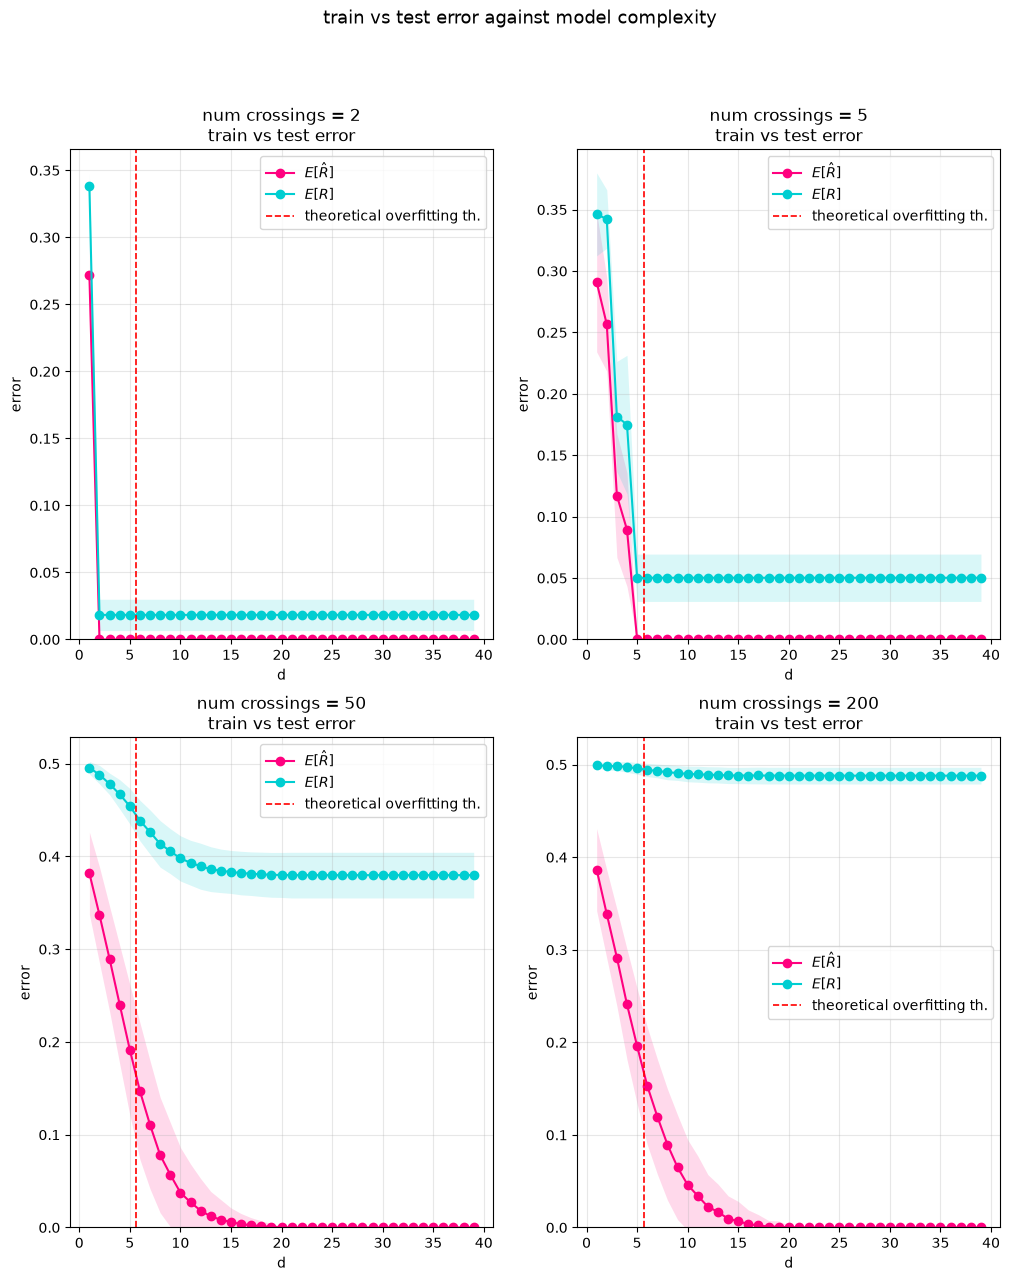

In [71]:
fig, axs = plt.subplots(2, 2, figsize=(12, 14))
fig.suptitle(r'train vs test error against model complexity', fontsize=13)

# fader to be tuned
noise_std = 0
num_iter = 100
data_size_tr = 50
supp_size = 10_000
data_size_test = 20_000
my_nums_crossings = [2,5,50,200 ]

for ax, my_num_crossings in zip(axs.flat, my_nums_crossings):
    gen_fun = partial(sine, m=my_num_crossings)

    # build test set
    x_test = sample_x(data_size_test, supp_size)
    y_test = sample_y(x=x_test, f=gen_fun, sigma=noise_std)

    # build models and do plots 
    hat_Rs, Rs, gaps, std_hat_Rs, std_Rs, std_gaps, predictions, x, y, x_grid = main_loop(
        x_test, y_test, n=data_size_tr, sigma=noise_std, T=num_iter, model=mymodel, f=gen_fun, N=supp_size)
    plots(hat_Rs, Rs, gaps, std_hat_Rs=std_hat_Rs, std_Rs=std_Rs, std_gaps=std_gaps, 
          n=data_size_tr, sigma=noise_std, T=num_iter, model=mymodel, 
        two=False, three=False, axes=[ax])
    ax.set_title(f'num crossings = {my_num_crossings}\ntrain vs test error')

Cioè, questo effetto della funzione $m$ c'è anche se non ho rumore, perché diventa difficile imparare la funzione.

> **Errore di train**: dipende da se riesco ad imparare I DATI

> **Errore di test**: dipende da se riesco ad imparare LA FUNZIONE


### Overfitting 

C'è un tradeoff nell'aumentare la depth: danno di adattarsi al rumore del train, e gain di classificare meglio. Ogni tanto, l'errore di test sale all'aumentare della depth, a causa dell'overfitting ai punti di traininig. 

Quando vediamo l'overfitting e quando no?

- Se non c'è **noise**, non lo vedo mai;

- all'aumentare del noise, ho due effetti: vedo più overfitting, ma allo stesso tempo le labels sono sempre più vicine ad essere casuali, quindi il test error non può NE' SCENDERE NE' SALIRE, NE' SCENDERE NE' SALIRE e rimane vicino a $0.5$ (quello che invece si vede bene è che aumenta il gap);

Anche la **complessità della funzione sotto** ha un ruolo:

- per un $m$ più piccolo, vedo più overfitting perché ho più libertà per fittare il rumore essendo la funzione sotto facile;

- per un $m$ più grande, ho troppo casino nell'imparare la funzione e quindi non fitto il rumore.

Inoltre, se ho $m$ grande ma aumento anche $n$, torno a vedere overfitting: un training set più grande mi annulla l'effetto di una funzione più complessa, perché ho modo di impararla meglio.

Il rapporto $n/N$ non ha effetto sull'overfitting. 


Dagli esperimenti fatti in precedenza, mi ricordo che c'era overfitting quando la funzione sotto è molto semplice.  

[checkpoint] bound: "naive" -> bound_naive, params: []


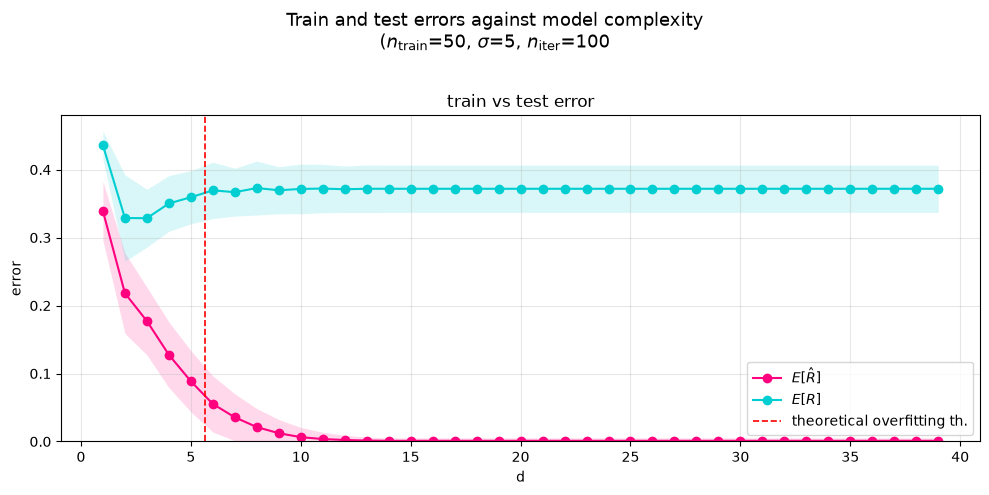

In [40]:
mymodel = DecisionTreeClassifier

from functools import partial

noise_std = 5
num_iter = 100
data_size_tr = 50
supp_size = 10_000
data_size_test = 20_000
num_crossings = 2

gen_fun = partial(sine, m=num_crossings)

x_test = sample_x(data_size_test, N = supp_size)
y_test = sample_y(x=x_test, f=gen_fun, sigma=noise_std)

hat_Rs, Rs, gaps, std_hat_Rs, std_Rs, std_gaps, predictions, x, y, x_grid = main_loop(
    x_test, y_test, n=data_size_tr, N = supp_size, sigma=noise_std, T=num_iter, model=mymodel, f=gen_fun)
plots(hat_Rs, Rs, gaps, std_hat_Rs=std_hat_Rs, std_Rs=std_Rs, std_gaps=std_gaps, n=data_size_tr, 
      sigma=noise_std, T=num_iter, model=mymodel,
      two = False, three = False)

Se io, da qui, aumento i punti di training, mi aspetto più overfitting perché li fitto meglio. 

[checkpoint] bound: "naive" -> bound_naive, params: []


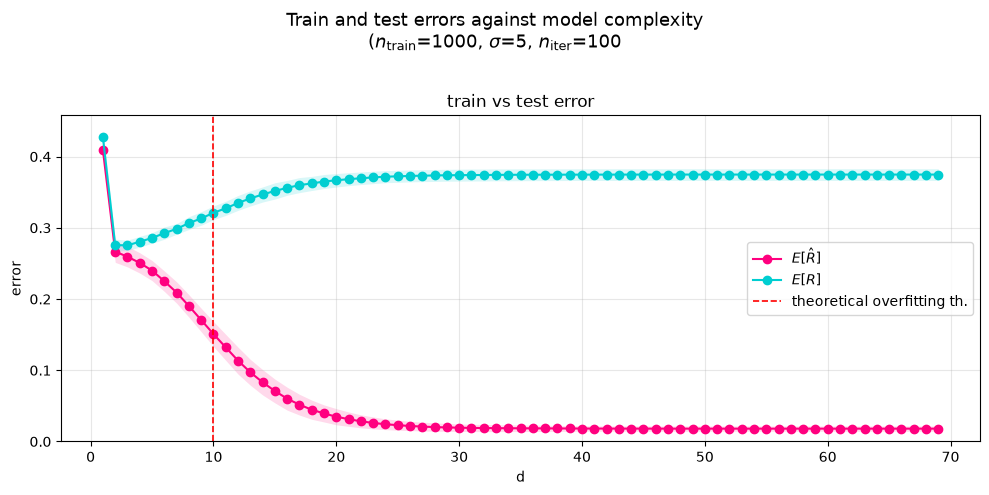

In [42]:
mymodel = DecisionTreeClassifier

from functools import partial

noise_std = 5
num_iter = 100
data_size_tr = 1000
supp_size = 10_000
data_size_test = 20_000
num_crossings = 2

gen_fun = partial(sine, m=num_crossings)

x_test = sample_x(data_size_test, N = supp_size)
y_test = sample_y(x=x_test, f=gen_fun, sigma=noise_std)

hat_Rs, Rs, gaps, std_hat_Rs, std_Rs, std_gaps, predictions, x, y, x_grid = main_loop(
    x_test, y_test, n=data_size_tr, N = supp_size, sigma=noise_std, T=num_iter, model=mymodel, f=gen_fun)
plots(hat_Rs, Rs, gaps, std_hat_Rs=std_hat_Rs, std_Rs=std_Rs, std_gaps=std_gaps, n=data_size_tr, 
      sigma=noise_std, T=num_iter, model=mymodel,
      two = False, three = False)

Mi aspetto lo stesso se aumento il noise

[checkpoint] bound: "naive" -> bound_naive, params: []


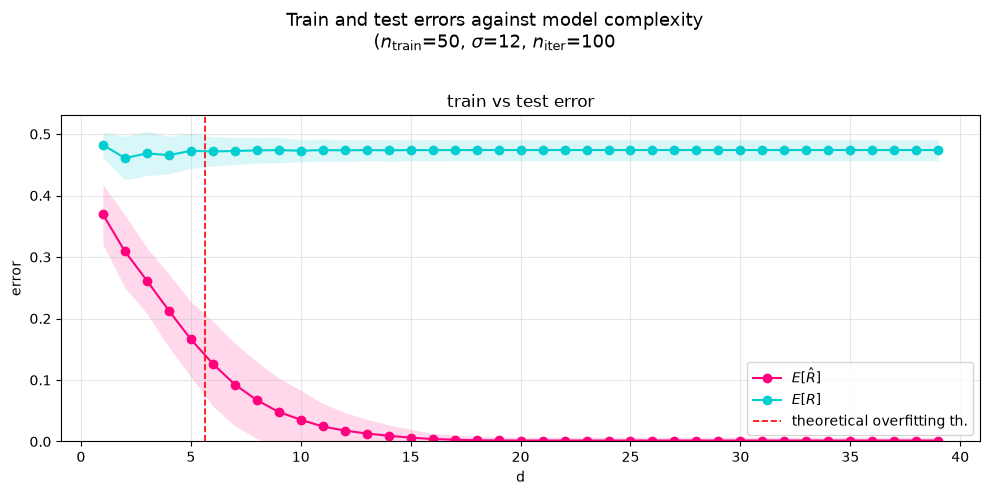

In [43]:
mymodel = DecisionTreeClassifier

from functools import partial

noise_std = 12
num_iter = 100
data_size_tr = 50
supp_size = 10_000
data_size_test = 20_000
num_crossings = 2

gen_fun = partial(sine, m=num_crossings)

x_test = sample_x(data_size_test, N = supp_size)
y_test = sample_y(x=x_test, f=gen_fun, sigma=noise_std)

hat_Rs, Rs, gaps, std_hat_Rs, std_Rs, std_gaps, predictions, x, y, x_grid = main_loop(
    x_test, y_test, n=data_size_tr, N = supp_size, sigma=noise_std, T=num_iter, model=mymodel, f=gen_fun)
plots(hat_Rs, Rs, gaps, std_hat_Rs=std_hat_Rs, std_Rs=std_Rs, std_gaps=std_gaps, n=data_size_tr, 
      sigma=noise_std, T=num_iter, model=mymodel,
      two = False, three = False)

No, forse perché se la funzione sotto è troppo semplice e ho tanto noise, non faccio in tempo a overfittare i dati di training nel senso che per i dati di test sarà già indifferente. 

[checkpoint] bound: "naive" -> bound_naive, params: []


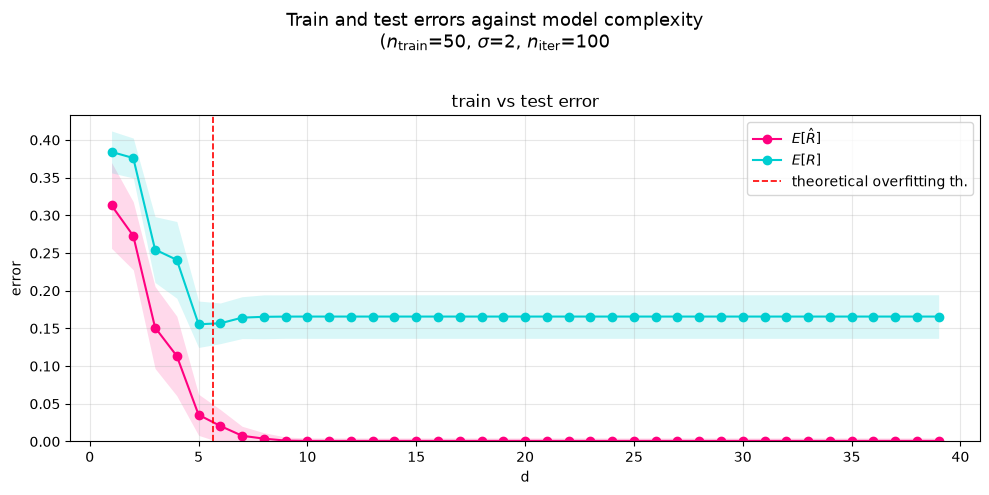

In [ ]:
mymodel = DecisionTreeClassifier

from functools import partial

noise_std = 2
num_iter = 100
data_size_tr = 50
supp_size = 10_000
data_size_test = 20_000
num_crossings = 5

gen_fun = partial(sine, m=num_crossings)

x_test = sample_x(data_size_test, N = supp_size)
y_test = sample_y(x=x_test, f=gen_fun, sigma=noise_std)

hat_Rs, Rs, gaps, std_hat_Rs, std_Rs, std_gaps, predictions, x, y, x_grid = main_loop(
    x_test, y_test, n=data_size_tr, N = supp_size, sigma=noise_std, T=num_iter, model=mymodel, f=gen_fun)
plots(hat_Rs, Rs, gaps, std_hat_Rs=std_hat_Rs, std_Rs=std_Rs, std_gaps=std_gaps, n=data_size_tr, 
      sigma=noise_std, T=num_iter, model=mymodel,
      two = False, three = False)

Così un po' lo vedo. Penso ci debba essere un buon rapporto tra il noise e la funzione sotto, perché se la funzione sotto è troppo semplice e ho tanto noise, da un lato overfitto ma dall'altro nel test non vedrò più nulla perché tutti i modelli sono uguali alla fine.

L'errore ha un doppio effetto: da un lato, mi fa fittare i dati di training meglio e in modo più lontano per i dati di test (aumenta il gap e vedo un po' di risalita), dall'altro, fa si che le labels siano quasi casuali e quindi sui dati di test l'errore resta vicino a $1/2$ e non vedo tanta risalita. 

Facciamo così: lasicamo una certa complessità della funzione sotto e aumentiamo solo il noise

[checkpoint] bound: "naive" -> bound_naive, params: []
[checkpoint] bound: "naive" -> bound_naive, params: []


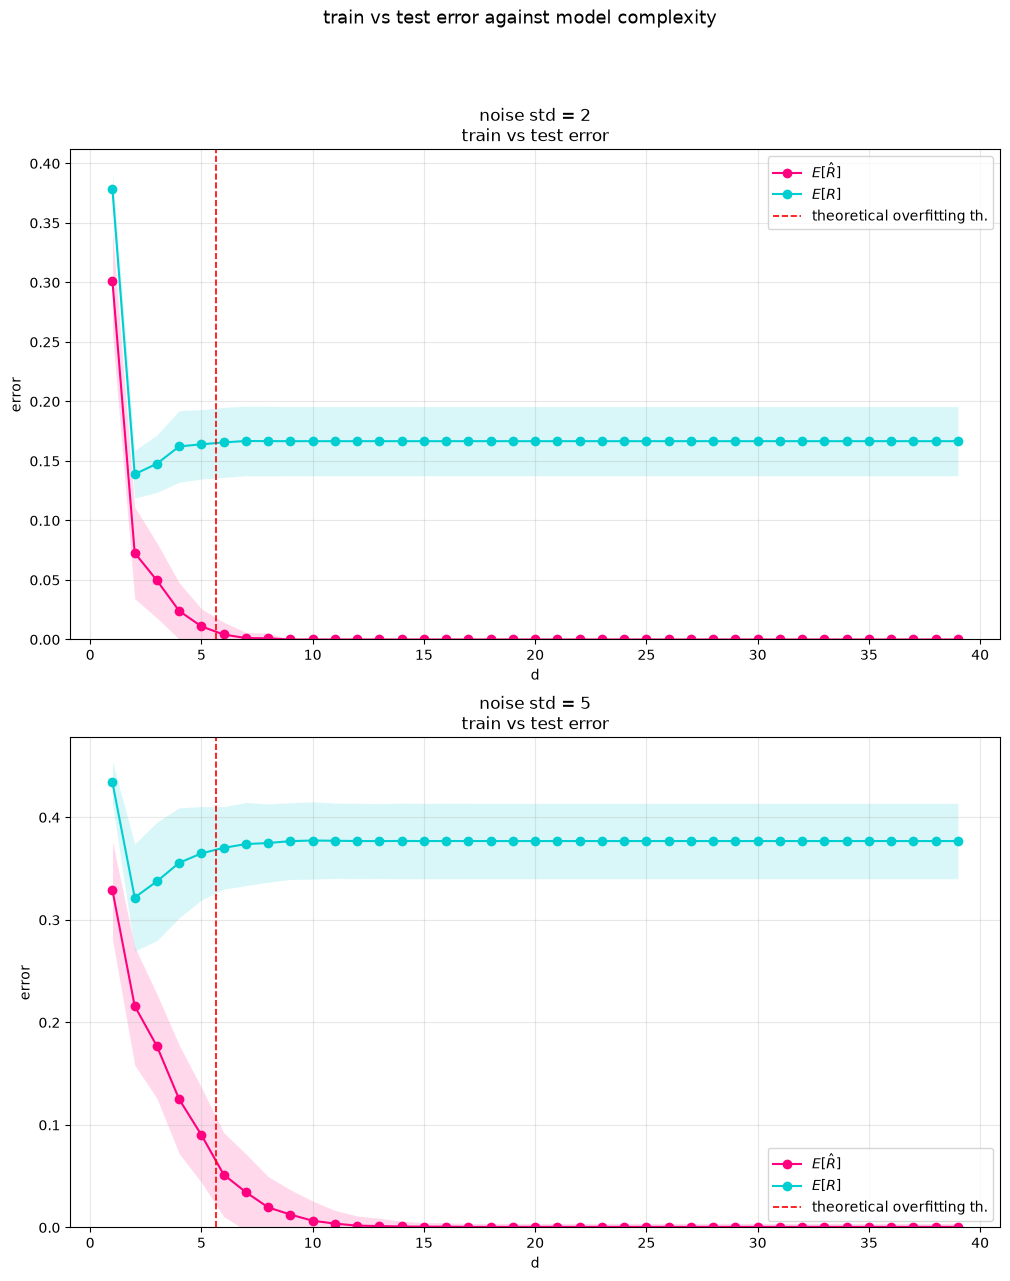

In [58]:
fig, axs = plt.subplots(2, 1, figsize=(12, 14))
fig.suptitle(r'train vs test error against model complexity', fontsize=13)

# fader to be tuned
my_noise_stds = [2,5]
num_iter = 100
data_size_tr = 50
supp_size = 10_000
data_size_test = 20_000
num_crossings = 2

gen_fun = partial(sine, m=num_crossings)


for ax, my_noise_std in zip(axs.flat, my_noise_stds):

    # build test set
    x_test = sample_x(data_size_test, supp_size)
    y_test = sample_y(x=x_test, f=gen_fun, sigma=my_noise_std)

    # build models and do plots 
    hat_Rs, Rs, gaps, std_hat_Rs, std_Rs, std_gaps, predictions, x, y, x_grid = main_loop(
        x_test, y_test, n=data_size_tr, sigma=my_noise_std, T=num_iter, model=mymodel, f=gen_fun, N=supp_size)
    plots(hat_Rs, Rs, gaps, std_hat_Rs=std_hat_Rs, std_Rs=std_Rs, std_gaps=std_gaps, 
          n=data_size_tr, sigma=my_noise_std, T=num_iter, model=mymodel, 
        two=False, three=False, axes=[ax])
    ax.set_title(f'noise std = {my_noise_std}\ntrain vs test error')

You see the gap increases

[checkpoint] bound: "naive" -> bound_naive, params: []
[checkpoint] bound: "naive" -> bound_naive, params: []


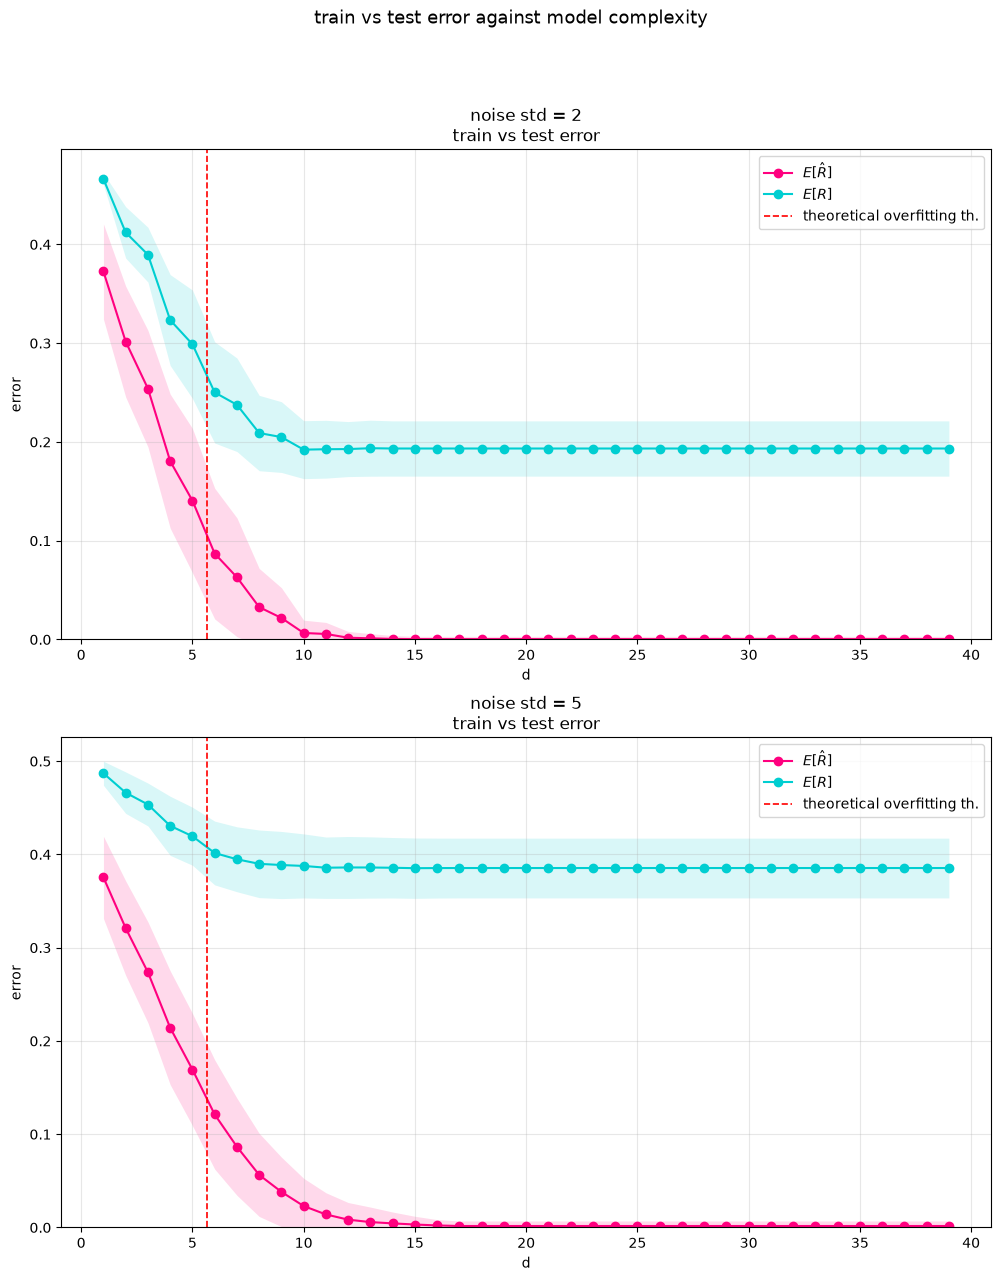

In [59]:
fig, axs = plt.subplots(2, 1, figsize=(12, 14))
fig.suptitle(r'train vs test error against model complexity', fontsize=13)

# fader to be tuned
my_noise_stds = [2,5]
num_iter = 100
data_size_tr = 50
supp_size = 10_000
data_size_test = 20_000
num_crossings = 10

gen_fun = partial(sine, m=num_crossings)

for ax, my_noise_std in zip(axs.flat, my_noise_stds):

    # build test set
    x_test = sample_x(data_size_test, supp_size)
    y_test = sample_y(x=x_test, f=gen_fun, sigma=my_noise_std)

    # build models and do plots 
    hat_Rs, Rs, gaps, std_hat_Rs, std_Rs, std_gaps, predictions, x, y, x_grid = main_loop(
        x_test, y_test, n=data_size_tr, sigma=my_noise_std, T=num_iter, model=mymodel, f=gen_fun, N=supp_size)
    plots(hat_Rs, Rs, gaps, std_hat_Rs=std_hat_Rs, std_Rs=std_Rs, std_gaps=std_gaps, 
          n=data_size_tr, sigma=my_noise_std, T=num_iter, model=mymodel, 
        two=False, three=False, axes=[ax])
    ax.set_title(f'noise std = {my_noise_std}\ntrain vs test error')

[checkpoint] bound: "naive" -> bound_naive, params: []
[checkpoint] bound: "naive" -> bound_naive, params: []


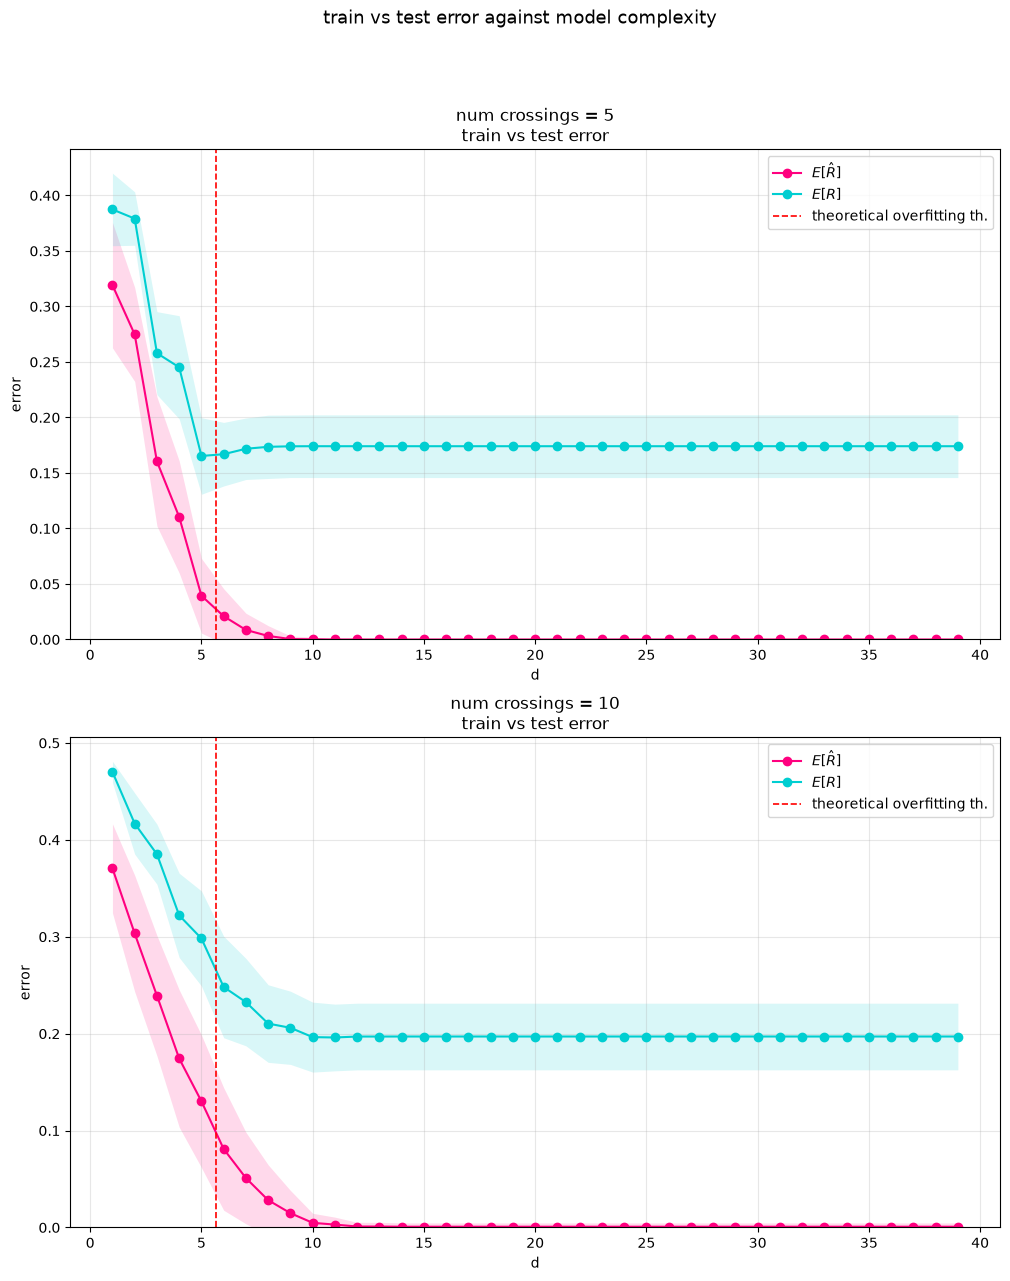

In [72]:
fig, axs = plt.subplots(2, 1, figsize=(12, 14))
fig.suptitle(r'train vs test error against model complexity', fontsize=13)

# fader to be tuned
noise_std = 2
num_iter = 100
data_size_tr = 50
supp_size = 10_000
data_size_test = 20_000
my_nums_crossings = [5, 10]

for ax, my_num_crossings in zip(axs.flat, my_nums_crossings):
    gen_fun = partial(sine, m=my_num_crossings)

    # build test set
    x_test = sample_x(data_size_test, supp_size)
    y_test = sample_y(x=x_test, f=gen_fun, sigma=noise_std)

    # build models and do plots 
    hat_Rs, Rs, gaps, std_hat_Rs, std_Rs, std_gaps, predictions, x, y, x_grid = main_loop(
        x_test, y_test, n=data_size_tr, sigma=noise_std, T=num_iter, model=mymodel, f=gen_fun, N=supp_size)
    plots(hat_Rs, Rs, gaps, std_hat_Rs=std_hat_Rs, std_Rs=std_Rs, std_gaps=std_gaps, 
          n=data_size_tr, sigma=noise_std, T=num_iter, model=mymodel, 
        two=False, three=False, axes=[ax])
    ax.set_title(f'num crossings = {my_num_crossings}\ntrain vs test error')

Man mano che aumento il numero di crossings, non lo vedo più perché l'errore viene "annullato" dal fatto che sto anche cercando di imparare la funzione. 

[checkpoint] bound: "naive" -> bound_naive, params: []


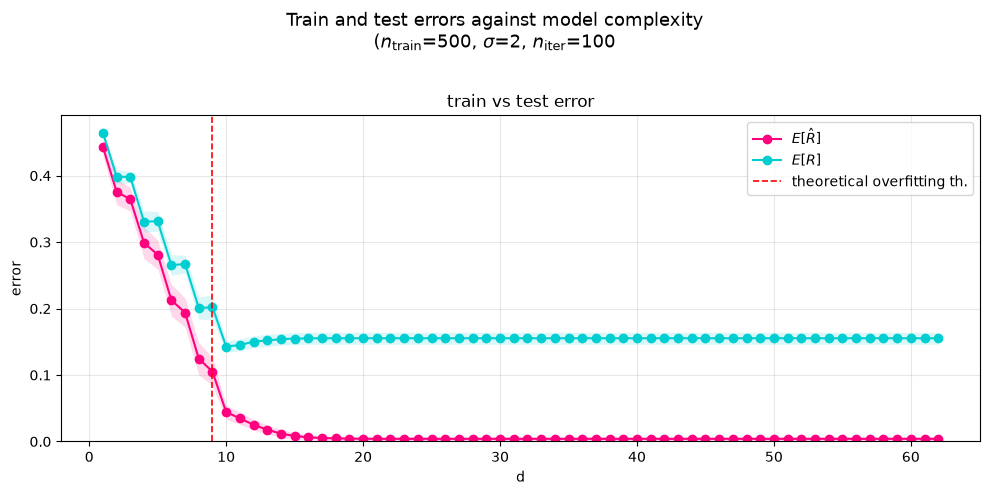

In [66]:
mymodel = DecisionTreeClassifier

from functools import partial

noise_std = 2
num_iter = 100
data_size_tr = 500
supp_size = 10_000
data_size_test = 20_000
num_crossings = 10

gen_fun = partial(sine, m=num_crossings)

x_test = sample_x(data_size_test, N = supp_size)
y_test = sample_y(x=x_test, f=gen_fun, sigma=noise_std)

hat_Rs, Rs, gaps, std_hat_Rs, std_Rs, std_gaps, predictions, x, y, x_grid = main_loop(
    x_test, y_test, n=data_size_tr, N = supp_size, sigma=noise_std, T=num_iter, model=mymodel, f=gen_fun)
plots(hat_Rs, Rs, gaps, std_hat_Rs=std_hat_Rs, std_Rs=std_Rs, std_gaps=std_gaps, n=data_size_tr, 
      sigma=noise_std, T=num_iter, model=mymodel,
      two = False, three = False)

Se tengo lo stesso noise e numero di crossings, ma aumento il numero di dati di training, riuscirò ad imparare un po' meglio quel modello e quindi posso anche fittare il noise. Cioè più dati $n$ annullano l'effetto di una maggiore complessità $m$. 

[checkpoint] bound: "naive" -> bound_naive, params: []


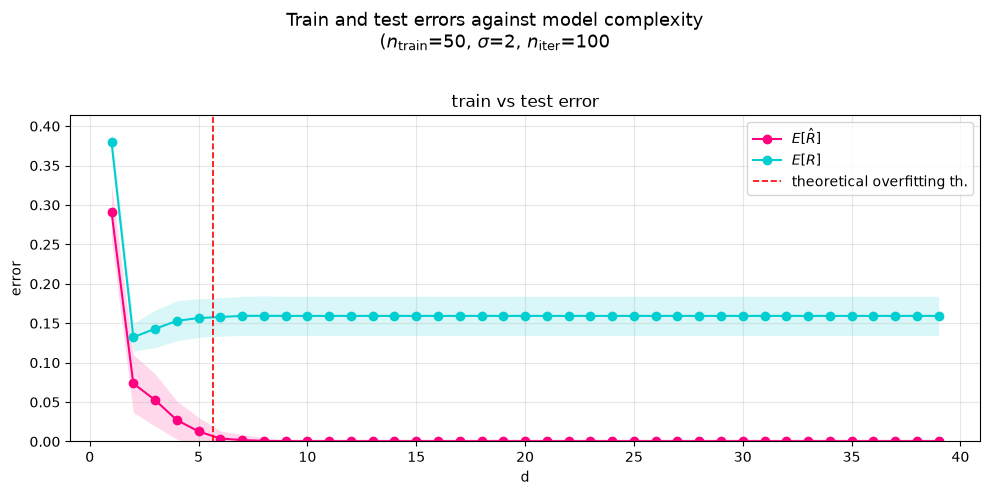

In [62]:
mymodel = DecisionTreeClassifier

from functools import partial

noise_std = 2
num_iter = 100
data_size_tr = 50
supp_size = 10_000
data_size_test = 20_000
num_crossings = 2

gen_fun = partial(sine, m=num_crossings)

x_test = sample_x(data_size_test, N = supp_size)
y_test = sample_y(x=x_test, f=gen_fun, sigma=noise_std)

hat_Rs, Rs, gaps, std_hat_Rs, std_Rs, std_gaps, predictions, x, y, x_grid = main_loop(
    x_test, y_test, n=data_size_tr, N = supp_size, sigma=noise_std, T=num_iter, model=mymodel, f=gen_fun)
plots(hat_Rs, Rs, gaps, std_hat_Rs=std_hat_Rs, std_Rs=std_Rs, std_gaps=std_gaps, n=data_size_tr, 
      sigma=noise_std, T=num_iter, model=mymodel,
      two = False, three = False)

Senza rumore, non c'è overfitting, whatever $m$. 

Se tu ci metti un pochino di rumore e una funzione sotto abbastanza semplice, vedi l'overfitting. Perché la funzione da imparare sarebbe semplice e quindi ho un sacco di gradi di libertà per fittare bene il rumore. 

Se aumenti il rumore, non lo vedi più perché ti avvicini al caso di labels casuali. Il gap aumenta e l'errore di test non sale né scende molto, resta vicino a $0.5$. 

Se aumenti la complessità della funzione sotto,  non vedi la risalita perché c'è troppo casino nell'imparare la funzione complicata, però rispetto al caso col rumore, il gap non aumenta di molto e quindi vedi bene che scende. 

Inoltre, la size del training set ha un effetto annullante della complessità della funzione, cioè se prendo $n$ più grande riesco ad imparare meglio la funzione e quindi vedo overfitting. 

[checkpoint] bound: "naive" -> bound_naive, params: []
[checkpoint] bound: "naive" -> bound_naive, params: []
[checkpoint] bound: "naive" -> bound_naive, params: []


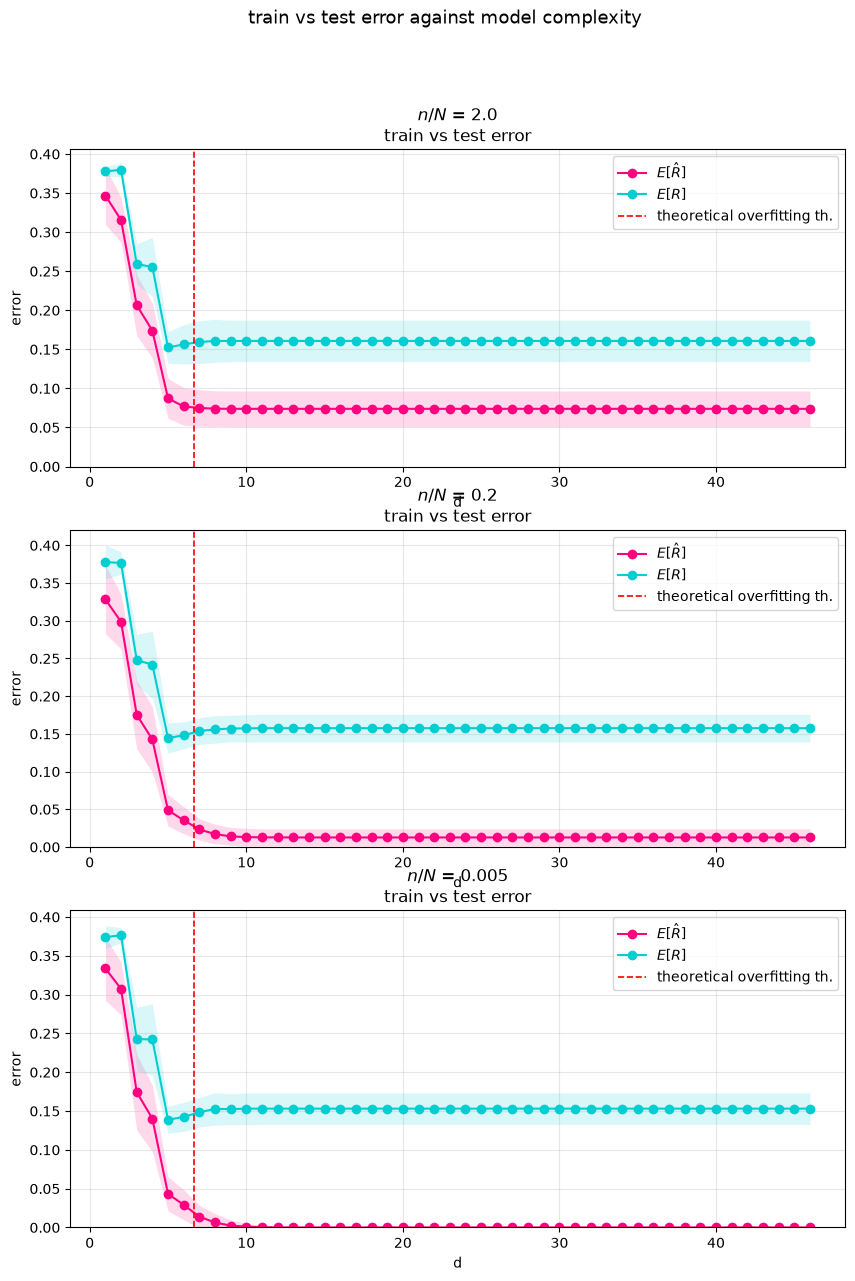

In [70]:
fig, axs = plt.subplots(3, 1, figsize=(10, 14))
fig.suptitle(r'train vs test error against model complexity', fontsize=13)

# fader to be tuned
noise_std = 2
num_iter = 100
data_size_tr = 100
my_supp_sizes = [50, 500, 20_000]
data_size_test = 20_000
num_crossings = 5

for ax, my_supp_size in zip(axs.flat, my_supp_sizes):
    gen_fun = partial(sine, m=num_crossings)

    # build test set
    x_test = sample_x(data_size_test, N = my_supp_size)
    y_test = sample_y(x=x_test, f=gen_fun, sigma=noise_std)

    # build models and do plots 
    hat_Rs, Rs, gaps, std_hat_Rs, std_Rs, std_gaps, predictions, x, y, x_grid = main_loop(
        x_test, y_test, n=data_size_tr, sigma=noise_std, T=num_iter, model=mymodel, f=gen_fun, N=my_supp_size)
    plots(hat_Rs, Rs, gaps, std_hat_Rs=std_hat_Rs, std_Rs=std_Rs, std_gaps=std_gaps, 
          n=data_size_tr, sigma=noise_std, T=num_iter, model=mymodel, 
        two=False, three=False, axes=[ax])
    ax.set_title(f'$n/N$ = {100/my_supp_size}\ntrain vs test error')

Aumenta il gap per i discorsi fatti sopra, ma non cambia l'overfitting. 

### ALL IN ALL

> **train error** dipende da quanto imparo I DATI DI TRAINING 

> **test error** dipende da quanto imparo LA FUNZIONE SOTTO

- **gap tra train e test error** 
    > se c'è noise, c'è sempre un gap, che aumenta con esso.  
    > se non c'è noise, ma $n<N$, ci sarà un gap.  
    > il gap non c'è se e solo se noise è 0 e $n > N$.   
    > aumenta anche con $m$ ma perché vado verso il caso test error = $0.5$

- **depth a cui satura il train error**
    > influenzata da $m$ insieme al noise, e da $n$  
    > il test error può saturare un po' prima perché dopo un po' gli è lo stesso (a causa di noise e $n/N$)

- **valore a cui satura il train error**
    > è $0$ se e solo se $n<N$ oppure $n>N$ senza noise. 

- **valore a cui satura il test error**
    > è influenzato dal noise, da $m$ (ché se è troppo complicata, è come fossero labels casuali), e da $n/N$

- **overfitting**
    > è influenzato da noise (ma con duplice effetto di rendere le label casuali), e da $m$ in relazione ad $n$


> il **noise** influenza sempre bene il gap tra il train e test error. questo non può essere $0$ se c'è noise. 

> l'effetto di una **complessità** maggiore è inibito se aumento $n$.

Gli alberi non fanno sempre quello che ci aspettiamo perché scelgono ogni split indipendentemente da quelli dopo, quindi il modello appreso potrebbe non essere il migliore a cui posso pensare io con quella depth, perché questo richiede degli split non ottimali alle depth precedenti. 
